# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = 1920 * 1080 * 3 * 1 / 1024**2          # W x H x C x B (8 bits = 1 byte)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 3600

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = 400 * frames_per_day * (1920 * 1080 * 3) / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = 400 * (10 * 24 * 3600) * (640 * 360 * 3) / 1024**4
pct_pixels_remaining = 100 * (640 * 360) / (1920 * 1080)

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

**Spatial:** at 640x360 only 11.1% of the pixels remain (3x fewer along each axis), so fine detail such as a licence-plate character, a face, a logo or a small object in someone's hand is averaged away. Raster interpolation can only invent smooth in-between values when we scale back up, so it can never bring that detail back.

**Temporal:** at 10 fps we keep 1 frame in 3. A person running at more than 25 px/s moves about three times further between frames, so the exact instant of a short event (an impact, a hand movement) can fall between frames, and it becomes harder to match the same person or object from one frame to the next (the correspondence problem).

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

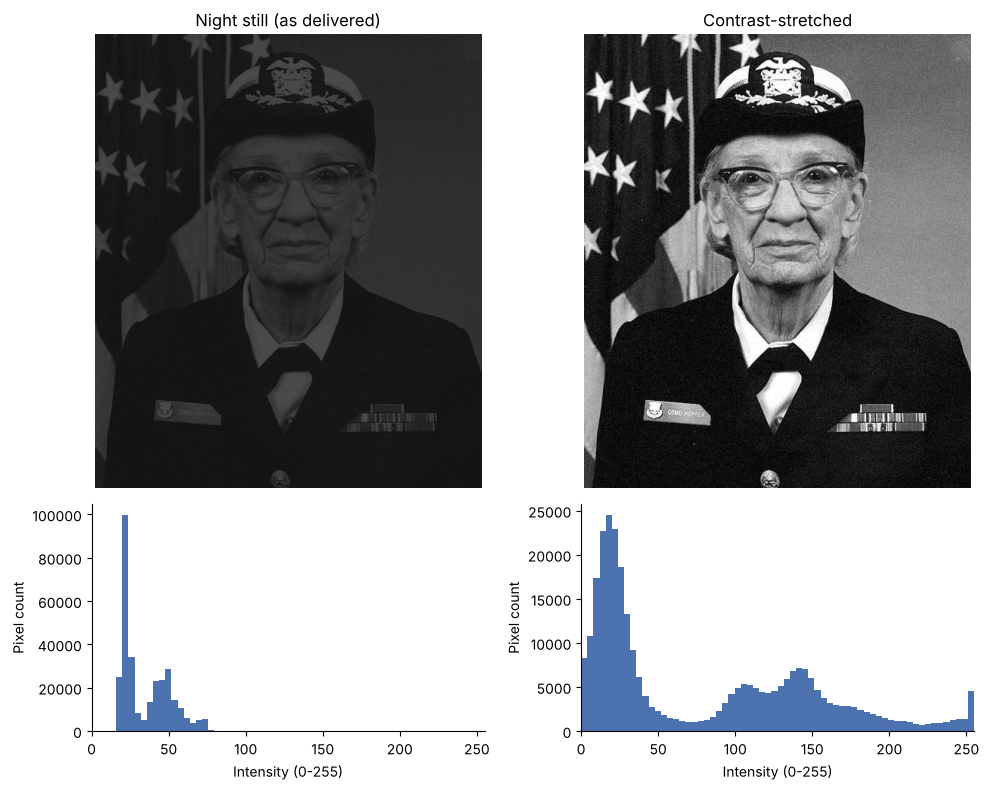

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - lo) / (hi - lo) * 255, 0, 255)

lo2, hi2 = np.percentile(stretched, [1, 99])
c_after = michelson(hi2, lo2)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
for j, (im, title) in enumerate([(night_still, "Night still (as delivered)"),
                                 (stretched, "Contrast-stretched")]):
    axes[0, j].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, j].set_title(title); axes[0, j].axis("off")
    axes[1, j].hist(im.ravel(), bins=64, range=(0, 255), color="#4C72B0")
    axes[1, j].set_xlim(0, 255)
    axes[1, j].set_xlabel("Intensity (0-255)"); axes[1, j].set_ylabel("Pixel count")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

**Shape:** the night histogram is dark (shifted to the far left), narrow (all pixels sit in roughly 15-78 out of 255), low-contrast and multi-modal (a big peak near 20, a smaller one near 50), with no pixels in the upper 70% of the range. Its Michelson contrast is 0.609 (1st-99th percentile). Note that 0.609 looks deceptively high only because the black level is already close to the sensor floor; the actual range used is about 55 grey levels.

**Why stretching helps:** the differences between objects were already in the data but squeezed into about 55 grey levels, which the eye cannot separate. The linear remap spreads them over 0-255, so the contrast becomes 1.0, but it only rescales existing values (noise is amplified too) and adds no new information. A histogram counts how many pixels have each intensity and throws away where they are, so many completely different images can share one histogram. It can diagnose the problem (under-exposed, narrow range) but could never tell us what is in the picture.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing (<3 px/s): 68.7 s -> 78.1 s  (257 frames)
Running (>25 px/s): 78.6 s -> 86.0 s  (223 frames)
Audio event: frame 2250 (t=75.00 s) | Lighting event: frame 3000 (t=100.00 s)


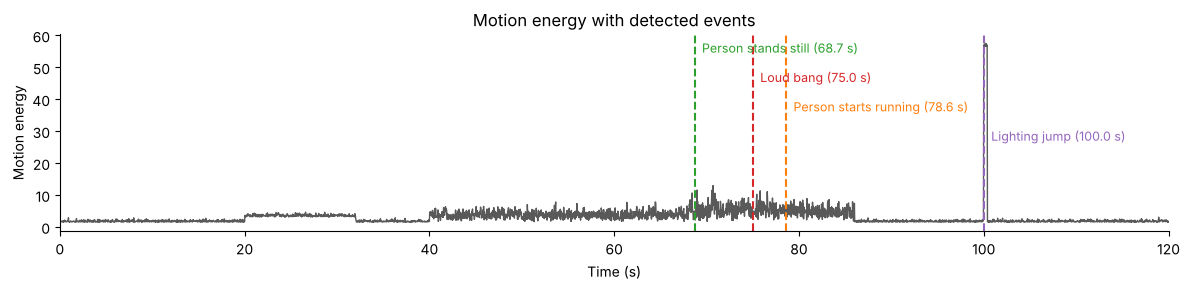

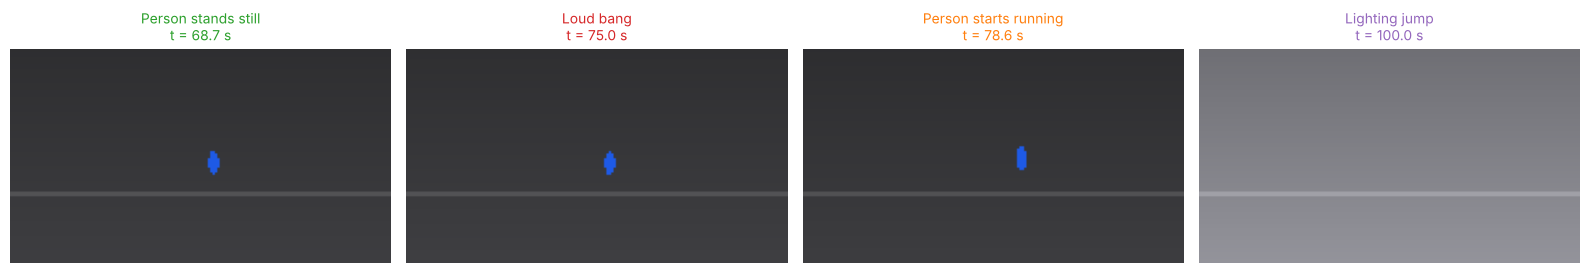

In [4]:
# TODO 1: person speed (px/s) -- motion vector over a 1 s window (FPS frames)
dx = cctv.person_x.diff(FPS)
dy = cctv.person_y.diff(FPS)
speed = np.hypot(dx, dy)            # displacement over 1 s = px/s
t = cctv.time_s.values

# TODO 2: standing / running time ranges (print the first and last time of each)
def span(mask, label):
    idx = np.flatnonzero(mask.values)
    if idx.size == 0:
        print(f"{label}: none"); return None
    print(f"{label}: {t[idx[0]]:.1f} s -> {t[idx[-1]]:.1f} s  ({idx.size} frames)")
    return idx[0], idx[-1]
standing = span(speed < 3, "Standing (<3 px/s)")
running  = span(speed > 25, "Running (>25 px/s)")

# TODO 3: event frame indices
audio_event_idx = int(np.argmax((cctv.audio_level_db > -20).values))
lighting_event_idx = int(np.flatnonzero((cctv.mean_brightness.diff().abs() > 40).values)[0])
print(f"Audio event: frame {audio_event_idx} (t={t[audio_event_idx]:.2f} s) | "
      f"Lighting event: frame {lighting_event_idx} (t={t[lighting_event_idx]:.2f} s)")

# events for the timeline: (frame index, label, colour)
events = [(standing[0], "Person stands still", "tab:green"),
          (running[0], "Person starts running", "tab:orange"),
          (audio_event_idx, "Loud bang", "tab:red"),
          (lighting_event_idx, "Lighting jump", "tab:purple")]
events.sort(key=lambda e: e[0])

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t, cctv.motion_energy, color="0.35", lw=1)
ymax = cctv.motion_energy.max()
for k, (i, lab, col) in enumerate(events):
    ax.axvline(t[i], color=col, ls="--", lw=1.5)
    ax.text(t[i] + 0.8, ymax * (0.95 - 0.16 * (k % 4)), f"{lab} ({t[i]:.1f} s)", color=col, fontsize=9)
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy"); ax.set_xlim(0, 120)
ax.set_title("Motion energy with detected events")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(4 * len(events), 2.6))
for ax, (i, lab, col) in zip(axes, events):
    ax.imshow(render_frame(cctv.iloc[i])); ax.axis("off")
    ax.set_title(f"{lab}\nt = {t[i]:.1f} s", color=col, fontsize=10)
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

The brief events would most likely be missed. Frames at 0, 20, 40, 60, 80, 100 and 120 s do not contain the bang at 75 s (it lasts about 2 s), the person standing still from 68.7 s, or the moment they start running at 78.6 s. The 100 s lighting change would only be caught by luck. Uniform sampling spends its frames on long quiet stretches and misses short events. The approach I used is **content-based (event-driven) keyframe extraction** from Slide 40: motion vectors and audio/brightness changes pick the frames, which gives one representative frame per event.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

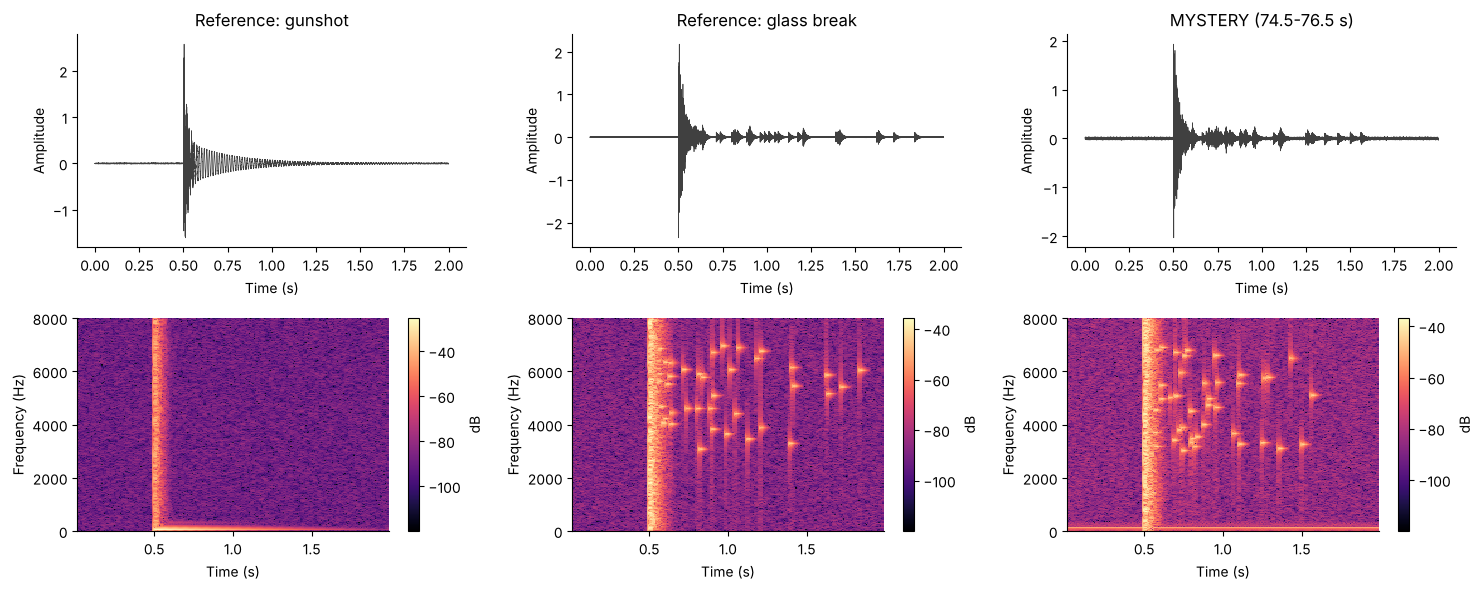

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.989, 'MYSTERY (74.5-76.5 s)': 0.873}
Verdict: the mystery sound is most likely a GLASS BREAK (HF fraction 0.87 vs glass 0.99 / gunshot 0.00; scattered high-frequency specks linger after the impact).


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}
tt = np.arange(int(2.0 * FS)) / FS

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for j, (name, x) in enumerate(clips.items()):
    axes[0, j].plot(tt, x, lw=0.5, color="0.25")
    axes[0, j].set_title(name); axes[0, j].set_xlabel("Time (s)"); axes[0, j].set_ylabel("Amplitude")
    f, ts, S = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    im = axes[1, j].pcolormesh(ts, f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma")
    axes[1, j].set_ylim(0, 8000); axes[1, j].set_xlabel("Time (s)"); axes[1, j].set_ylabel("Frequency (Hz)")
    fig.colorbar(im, ax=axes[1, j], label="dB")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    f, ts, S = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    win = (ts >= 0.5 + 0.2) & (ts <= 0.5 + 1.2)
    E = S[:, win]
    hf_fraction[name] = float(E[f > 3000].sum() / E.sum())

print({k: round(v, 3) for k, v in hf_fraction.items()})
# TODO 4: verdict
g, gl, m = (hf_fraction[k] for k in clips)
closest = "GLASS BREAK" if abs(m - gl) < abs(m - g) else "GUNSHOT"
print(f"Verdict: the mystery sound is most likely a {closest} "
      f"(HF fraction {m:.2f} vs glass {gl:.2f} / gunshot {g:.2f}; scattered high-frequency specks linger after the impact).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

No, not confidently. All three waveforms look the same: flat noise, then a sharp spike at the impact and a decay. The waveform shows *when* and *how loud* but not *what kind* of sound. The spectrogram adds the three dimensions of Slide 57: **time** (x), **frequency** (y) and **magnitude/intensity** (colour, in dB), so we can see which frequencies are present at each moment.

The deciding pattern was the **scattered high-frequency specks** after the initial vertical stripe. The glass reference and the mystery clip both show a vertical impact stripe followed by many short bright specks between 3 and 7 kHz. The gunshot shows a vertical stripe plus a low horizontal band (the 70 Hz boom) and then nothing. The numbers agree: the fraction of energy above 3 kHz in the 0.2-1.2 s after the impact is 0.003 for the gunshot, 0.989 for glass and 0.873 for the mystery sound, so it is a glass break.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

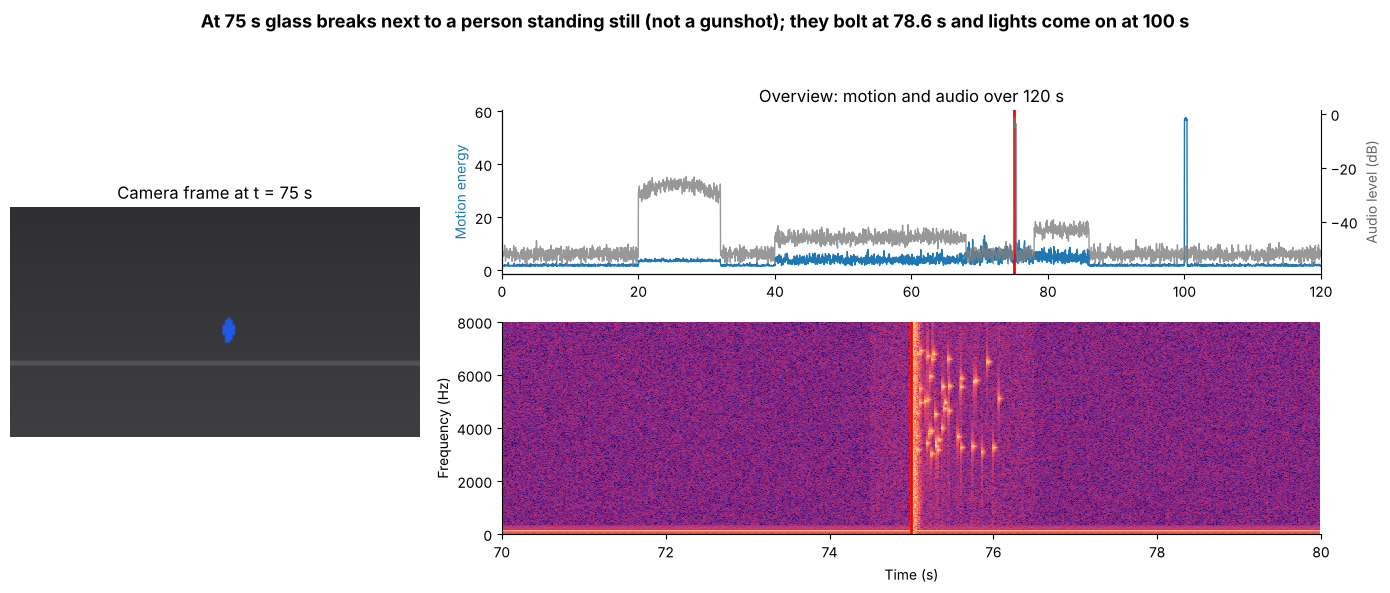

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
# 1. video frame at t_sel
ax_v = fig.add_subplot(gs[:, 0])
i_sel = int(round(t_sel * FPS))
ax_v.imshow(render_frame(cctv.iloc[i_sel])); ax_v.axis("off")
ax_v.set_title(f"Camera frame at t = {t_sel:.0f} s")

# 2. motion + audio timeline
ax_t = fig.add_subplot(gs[0, 1])
ax_t.plot(cctv.time_s, cctv.motion_energy, color="tab:blue", lw=1, label="Motion energy")
ax_t.set_ylabel("Motion energy", color="tab:blue"); ax_t.set_xlim(0, 120)
ax_a = ax_t.twinx()
ax_a.plot(cctv.time_s, cctv.audio_level_db, color="tab:gray", lw=1, alpha=0.8, label="Audio level")
ax_a.set_ylabel("Audio level (dB)", color="0.4"); ax_a.spines["right"].set_visible(True)
ax_t.axvline(t_sel, color="red", lw=2)
ax_t.set_title("Overview: motion and audio over 120 s")

# 3. spectrogram 70-80 s
ax_s = fig.add_subplot(gs[1, 1])
f, ts, S = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_s.pcolormesh(ts + 70, f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma")
ax_s.set_ylim(0, 8000); ax_s.set_xlim(70, 80)
ax_s.axvline(t_sel, color="red", lw=2)
ax_s.set_xlabel("Time (s)"); ax_s.set_ylabel("Frequency (Hz)")

# 4. conclusion-style title
fig.suptitle("At 75 s glass breaks next to a person standing still (not a gunshot); they bolt at 78.6 s and lights come on at 100 s",
             fontsize=13, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

The bang would appear to happen 2 s after it really did, around 77 s, which is close to the moment the person starts to run (78.6 s). The briefing would then suggest that the person ran in response to the sound, or that the bang happened while they were already moving, and the whole sequence of events would be wrong. A wrong time could also lead to the wrong video frame being used as evidence. The **spectrogram panel** would make the mistake visible: the red 75 s marker would sit on quiet background noise and the bright impact stripe would be about 2 s to the right of it. The audio line in the top timeline would show the same offset against the motion spike.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

**Final briefing:**

At 75 s on the Lot B camera a loud bang was recorded while one person was standing still (68.7-78.1 s); the person started running at 78.6 s and left the frame at about 86 s, and the lights came on at 100 s. The bang was **glass breaking, not a gunshot**: 87% of its energy above 3 kHz after the impact matches the glass reference (99%) and not the gunshot (0.3%), so this needs a break-in or vandalism response rather than a firearms response. If I could show only one visualization it would be the **spectrogram** (time x frequency x magnitude), because it is the only view that answers the question that decides the response, while the timeline and keyframes are for locating the moment (structure -> pattern -> change -> event -> meaning). Storing 400 cameras at 1080p/30 fps uncompressed would take about 5,866 TB per day, whereas 360p/10 fps takes about 217 TB per day (27x less, with 11% of the pixels per frame). I recommend storing the downsampled stream by default and keeping full resolution and frame rate only for event-triggered clips. Whatever we cut, we must **not** reduce the audio sampling rate below 16 kHz, because the high-frequency content above 3 kHz is the evidence that told glass from a gunshot.